In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns",None)
sns.set_theme(style="whitegrid")


Now I have imported the libraries I will use for EDA
and made all the columns to view and sns plots with white grid

In [4]:
df=pd.read_csv("../data/creditcard.csv")
print("Now I have loaded the dataset successfully")
print("shape:",df.shape)
print(df.head())

Now I have loaded the dataset successfully
shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9       V10       V11       V12       V13       V14  \
0  0.098698  0.363787  0.090794 -0.551600 -0.617801 -0.991390 -0.311169   
1  0.085102 -0.255425 -0.166974  1.612727  1.065235  0.489095 -0.143772   
2  0.247676 -1.514654  0.207643  0.624501  0.066084  0.717293 -0.165946   
3  0.377436 -1.387024 -0.054952 -0.226487  0.178228  0.507757 -0.287924   
4 -0.270533  0.817739  0.753074 -0.822843  0.538196  1.345852 -1.119670   


now I have loaded the dataset and viewed its values ,2 of its features (time,amount) and target(class) is given as it is but other 28 features are given as PCA components

In [6]:
print(df.columns.tolist())

df.info()

df.describe().T

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


now I have viewed the colums ,info and statistical information but everything here is PCA component except 3

In [9]:
print("Missing values:",df.isnull().sum().sum())
print("duplicate rows:",df.duplicated().sum())

print("\nMissing values by column:")
print(df.isnull().sum().sort_values(ascending=False).head())

Missing values: 0
duplicate rows: 1081

Missing values by column:
Time    0
V1      0
V2      0
V3      0
V4      0
dtype: int64


here there are some duplicate values and no null values are here

Class
0    284315
1       492
Name: count, dtype: int64

Percentage distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


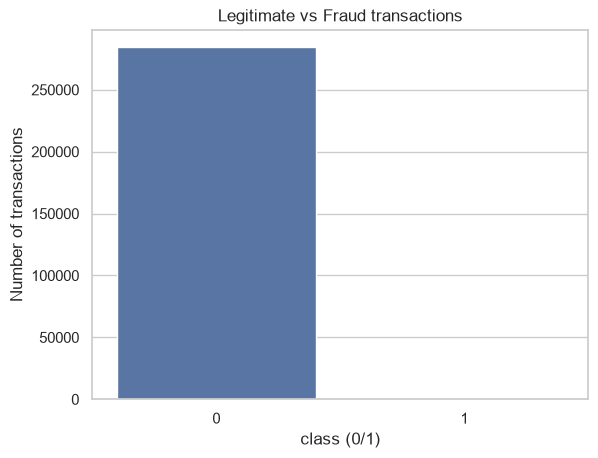

In [11]:
print(df["Class"].value_counts())

print("\nPercentage distribution:")
print(df["Class"].value_counts(normalize=True)*100)

sns.countplot(data=df,x="Class")
plt.title("Legitimate vs Fraud transactions")
plt.xlabel("class (0/1)")
plt.ylabel("Number of transactions")
plt.show()

now on seeing this we can conclude that this dataset is highly imbalanced dataset in the ratio 
0:1::99.82:0.17

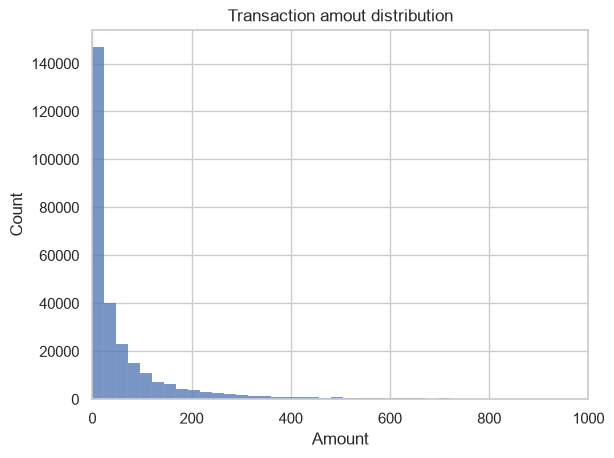

In [22]:
plt.title("Transaction amout distribution")
sns.histplot(data=df,x="Amount")
plt.xlim(0,1000)
plt.show()

many amout falls nearly 0 and less than 400


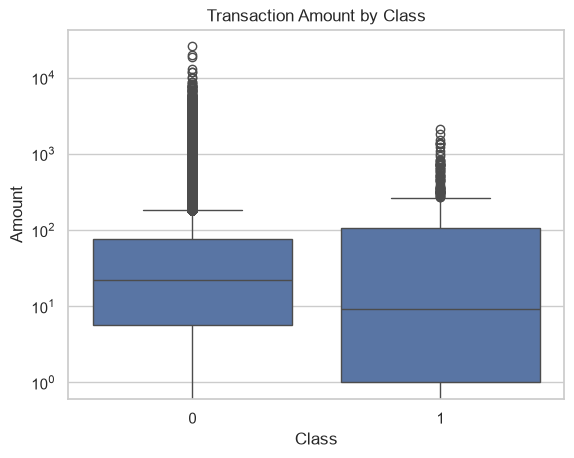

In [23]:
sns.boxplot(data=df, x="Class", y="Amount")
plt.yscale("log")
plt.title("Transaction Amount by Class")
plt.show()

we have visualised the box plot

In [26]:
correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .abs()
    .sort_values(ascending=False)
)

print(correlations)

V17       0.326481
V14       0.302544
V12       0.260593
V10       0.216883
V16       0.196539
V3        0.192961
V7        0.187257
V11       0.154876
V4        0.133447
V18       0.111485
V1        0.101347
V9        0.097733
V5        0.094974
V2        0.091289
V6        0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Time      0.012323
V28       0.009536
V24       0.007221
Amount    0.005632
V13       0.004570
V26       0.004455
V15       0.004223
V25       0.003308
V23       0.002685
V22       0.000805
Name: Class, dtype: float64


I have taken analyzed that PC 17,14,12,10,16 have some better relation with the class(target)

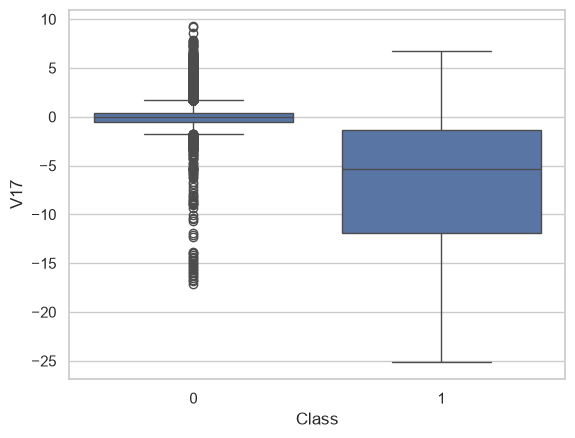

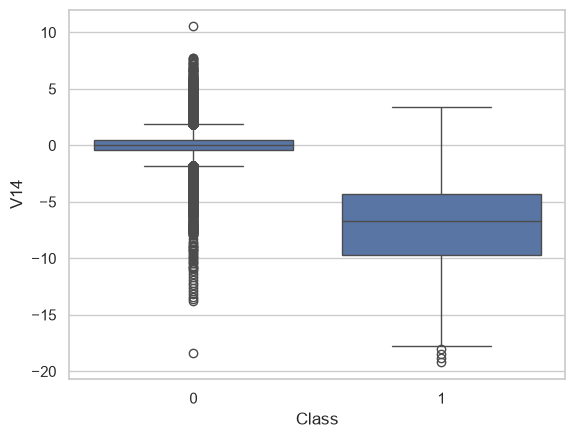

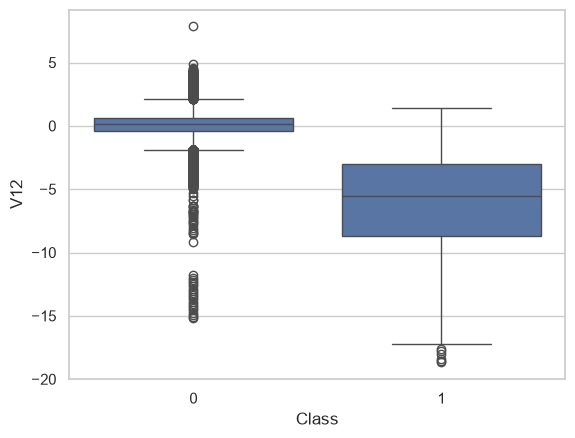

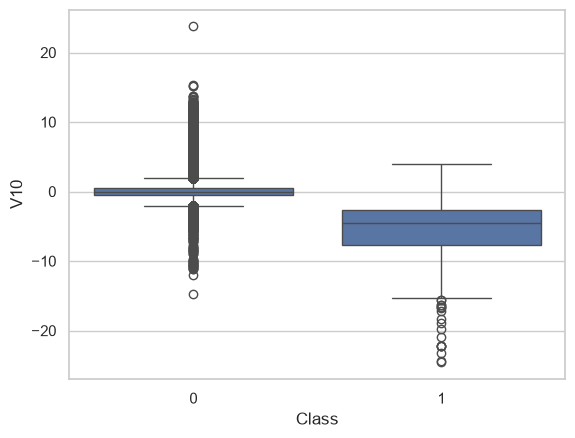

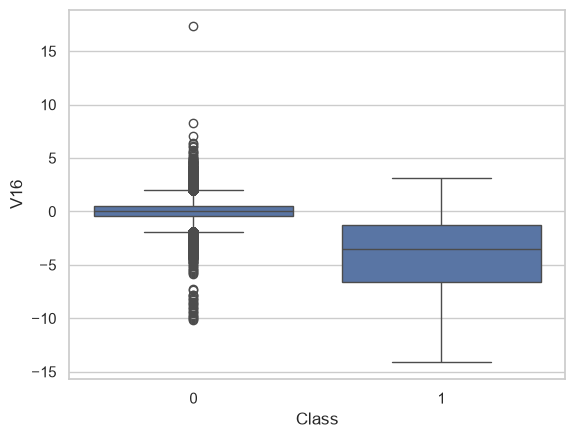

In [ ]:
best=["V17","V14","V12","V10","V16"]
for i in best:
    sns.boxplot(data=df,x="Class",y=i)
    plt.show()

Now we have visualized the boxplot for the first 5 components